<a href="https://colab.research.google.com/github/iqbaal24/PCVK_2026/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 – Morfologi Citra
**Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi**

Erosi, Dilasi, Opening, Closing, Top-hat, Black-hat, Skeleton, Thickening, dan Tugas Praktikum KTP.

> Pastikan gambar `plat nomer.jpg`, `kitten01.jpg`, `lily.jpg`, dan gambar KTP ada di folder `MyDrive/PCVK/Images/`.

## 1. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Import Library

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Folder gambar (ubah jika berbeda)
IMG = '/content/drive/MyDrive/PCVK/Images/'

## 3. Dilasi tanpa library morphology (SED Cross 3 x 3)
Fungsi dilasi dibuat manual: tiap piksel diganti nilai maksimum di area yang cocok dengan SED.

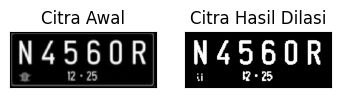

In [ ]:
def dilasi_citra(F, SED):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    ch = SED.shape[0] // 2   # setengah tinggi SED
    cw = SED.shape[1] // 2   # setengah lebar SED
    for i in range(ch, p - ch):
        for j in range(cw, q - cw):
            temp = F[i-ch:i+ch+1, j-cw:j+cw+1]
            imgD[i, j] = np.max(temp[SED == 1])
    return imgD

cross3 = np.array([[0,1,0],
                   [1,1,1],
                   [0,1,0]], dtype=np.uint8)

img_d = cv2.imread(IMG + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
imgD = dilasi_citra(thresh, cross3)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

## 4. Dilasi dengan library morphology OpenCV (SED Cross 3 x 3)

[[0 1 0]
 [1 1 1]
 [0 1 0]]


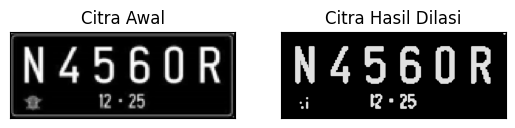

In [ ]:
img = cv2.imread(IMG + 'plat nomer.jpg')
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print(kernel)

plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(dilasi, cv2.COLOR_BGR2RGB)), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

## 5. Erosi tanpa library morphology (SE Square 5 x 5)
Tiap piksel diganti nilai minimum di area SE. Fungsi ini dipakai juga di nomor 7, 8, 11, dan 12.

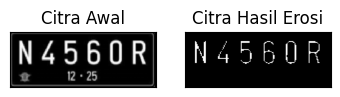

In [ ]:
def erosi_citra(F, SE):
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)
    ch = SE.shape[0] // 2
    cw = SE.shape[1] // 2
    for i in range(ch, m - ch):
        for j in range(cw, n - cw):
            temp = F[i-ch:i+ch+1, j-cw:j+cw+1]
            imgE[i, j] = np.min(temp[SE == 1])
    return imgE

img_e = cv2.imread(IMG + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
square5 = np.ones((5, 5), dtype=np.uint8)
imgE = erosi_citra(thresh1, square5)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

## 6. Erosi dengan library morphology OpenCV (SE Square 5 x 5)

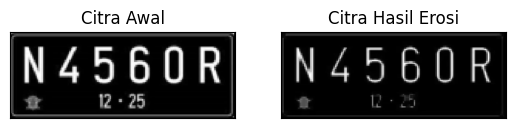

In [ ]:
img = cv2.imread(IMG + 'plat nomer.jpg')
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(erosion, cv2.COLOR_BGR2RGB)), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

## 7. Opening (SE Square) – tanpa dan dengan library
Opening = erosi lalu dilasi dengan SE yang sama.

**Tanpa library morphology** (SE Square 7 x 7 sesuai contoh modul)

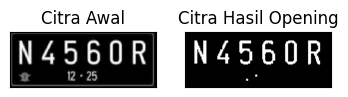

In [ ]:
img_o = cv2.imread(IMG + 'plat nomer.jpg', 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
SE7 = np.ones((7, 7), dtype=np.uint8)
imgO = dilasi_citra(erosi_citra(thresho, SE7), SE7)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

**Dengan library morphology** (SE Square 3 x 3)

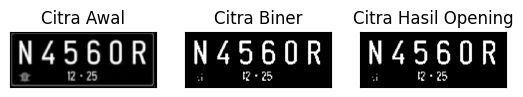

In [ ]:
img = cv2.imread(IMG + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

## 8. Closing (SE Square) – tanpa dan dengan library
Closing = dilasi lalu erosi dengan SE yang sama.

**Tanpa library morphology** (SE Square 7 x 7 sesuai contoh modul)

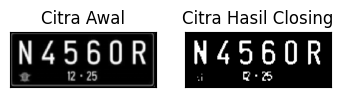

In [ ]:
img_c = cv2.imread(IMG + 'plat nomer.jpg', 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
imgC = erosi_citra(dilasi_citra(threshc, SE7), SE7)

plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

**Dengan library morphology** (SE Square 3 x 3)

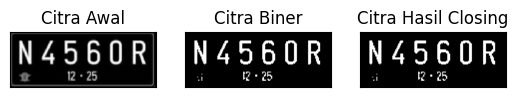

In [ ]:
img = cv2.imread(IMG + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

## 9. Dilasi dengan SE Cross 3 x 3 dan 5 x 5

SED = Cross 3


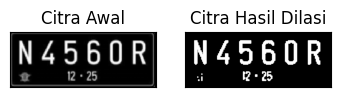

SED = Cross 5


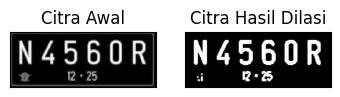

In [ ]:
cross5 = np.array([[0,0,1,0,0],
                   [0,0,1,0,0],
                   [1,1,1,1,1],
                   [0,0,1,0,0],
                   [0,0,1,0,0]], dtype=np.uint8)

img_d = cv2.imread(IMG + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

for nama, SED in [('SED = Cross 3', cross3), ('SED = Cross 5', cross5)]:
    print(nama)
    imgD = dilasi_citra(thresh, SED)
    plt.subplot(131), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

## 10. Dilasi dengan SE Circular 3 x 3 dan 5 x 5
SE lingkaran dibuat dengan `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, ...)`.

SED = Circle 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]


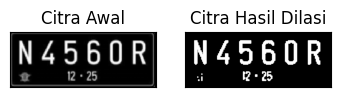

SED = Circle 5
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


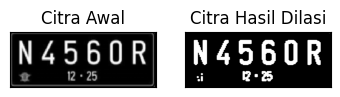

In [ ]:
img_d = cv2.imread(IMG + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

for w in (3, 5):
    print(f'SED = Circle {w}')
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    print(SED)
    imgD = dilasi_citra(thresh, SED)
    plt.subplot(131), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

## 11. Erosi dengan SE Rectangle 3 x 5 dan 5 x 7

SE = Rectangle 3x5


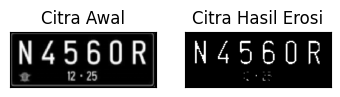

SE = Rectangle 5x7


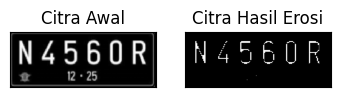

In [ ]:
img_e = cv2.imread(IMG + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

# (p = lebar, l = tinggi) -> 3x5 dan 5x7
for nama, p, l in [('SE = Rectangle 3x5', 5, 3), ('SE = Rectangle 5x7', 7, 5)]:
    print(nama)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
    imgE = erosi_citra(thresh1, SE)
    plt.subplot(131), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

## 12. Erosi dengan SE Line Vertikal 3 dan 5
Gunakan gambar `j.png` sesuai perintah modul.

SE = Line Vertikal 3


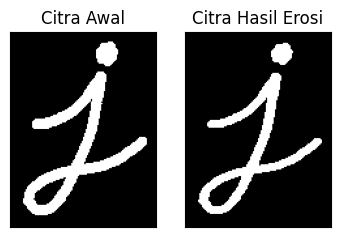

SE = Line Vertikal 5


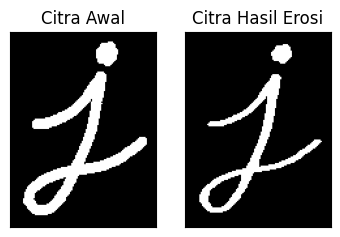

In [ ]:
img_e = cv2.imread(IMG + 'j.png', 0)
if img_e is None:   # cadangan bila j.png belum ada
    print('j.png tidak ditemukan, memakai plat nomer.jpg')
    img_e = cv2.imread(IMG + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

for k in (3, 5):
    print(f'SE = Line Vertikal {k}')
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))  # garis tegak
    imgE = erosi_citra(thresh1, SE)
    plt.subplot(131), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

## 13. Top Hat
Top-hat = citra asli dikurangi hasil opening. Menonjolkan objek terang yang lebih kecil dari SE.

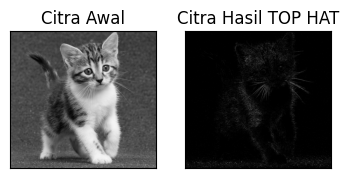

In [ ]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread(IMG + 'kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

## 14. Black Hat
Black-hat = hasil closing dikurangi citra asli. Menonjolkan objek gelap yang lebih kecil dari SE.

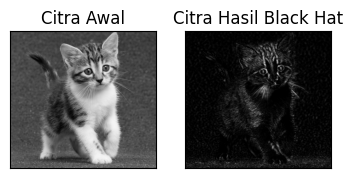

In [ ]:
img = cv2.imread(IMG + 'kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

## 15. Skeleton

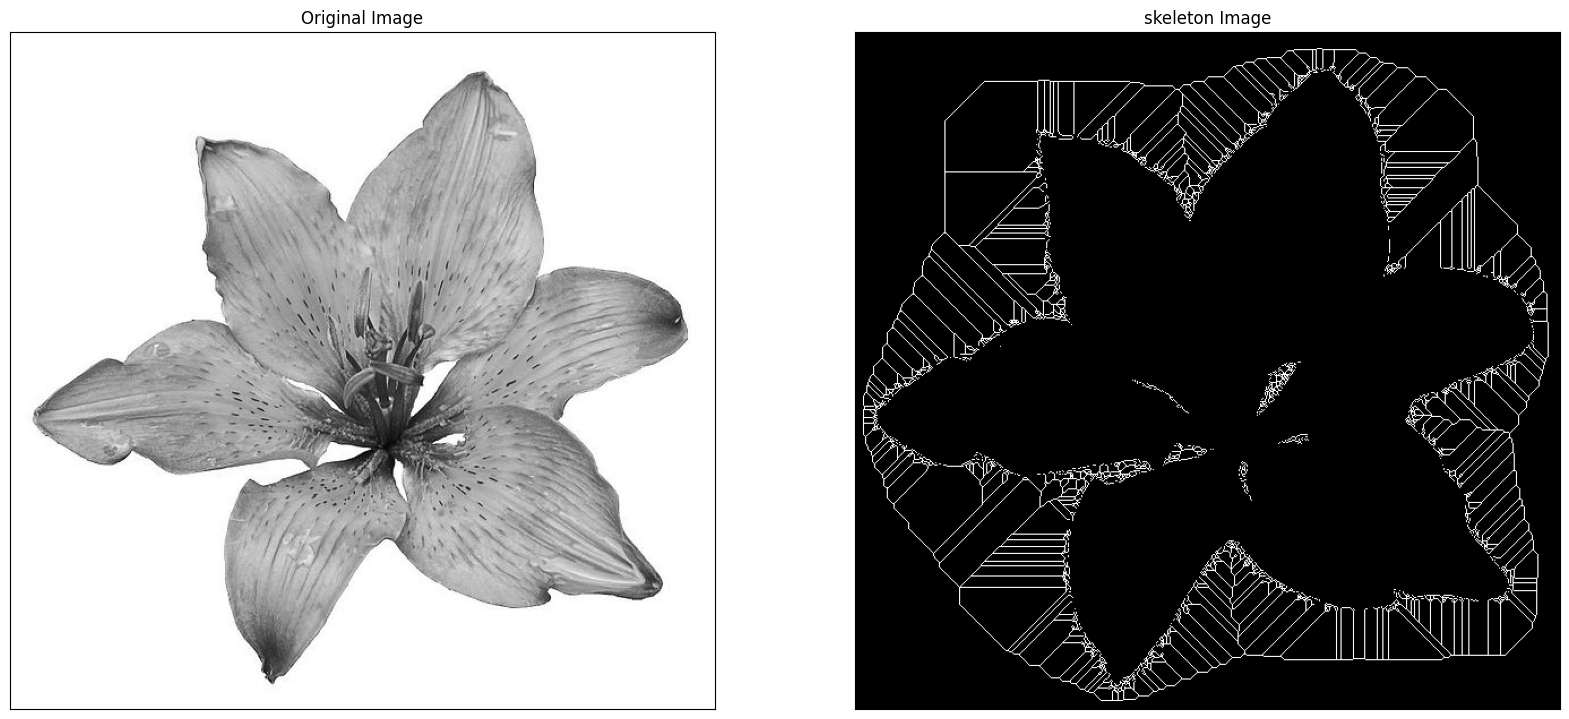

In [ ]:
import cv2 as cv
from skimage import filters
from skimage.morphology import skeletonize

img = cv.imread(IMG + 'lily.jpg', 0)
binary = img > filters.threshold_triangle(img)

# True/False menjadi 1/0
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(20, 20))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig('binary and bin_skeleton.png')
plt.show()

## 16. Skeleton Inverse

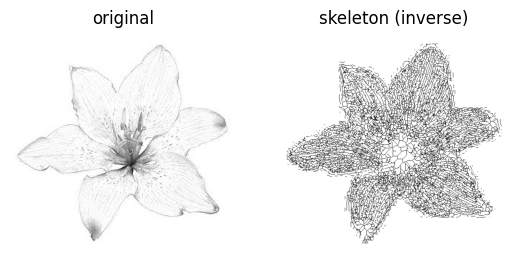

In [ ]:
from skimage import io

img = io.imread(IMG + 'lily.jpg')
if img.ndim == 3:
    img = img[..., 0]

# Bagian hitam dijadikan True, jadi pakai tanda <
binary = img < filters.threshold_triangle(img)
skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# colormap dibalik: gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

## 17. Thickening / Thinning

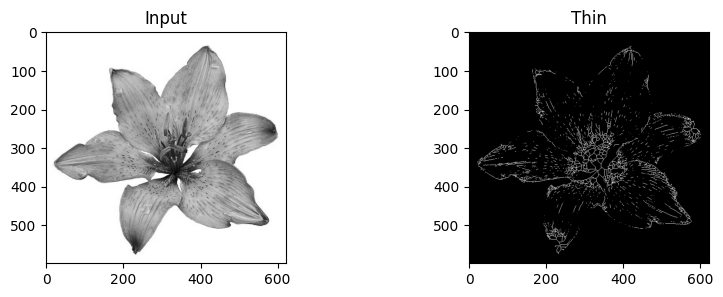

In [ ]:
from skimage import img_as_float, color, morphology

image = img_as_float(color.rgb2gray(io.imread(IMG + 'lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.savefig('/tmp/char_out.png')
plt.show()

## E. Tugas Praktikum – Morfologi pada Citra KTP
Tujuan: membuat teks KTP terbaca lebih baik oleh OCR dengan bantuan teknik morfologi. Caranya: baca KTP, ubah ke biner, bersihkan noise dengan opening/closing, tebalkan huruf dengan dilasi, lalu bandingkan hasil OCR dengan dan tanpa morfologi.

In [ ]:
!apt-get -qq install tesseract-ocr tesseract-ocr-ind > /dev/null
!pip -q install pytesseract
import pytesseract

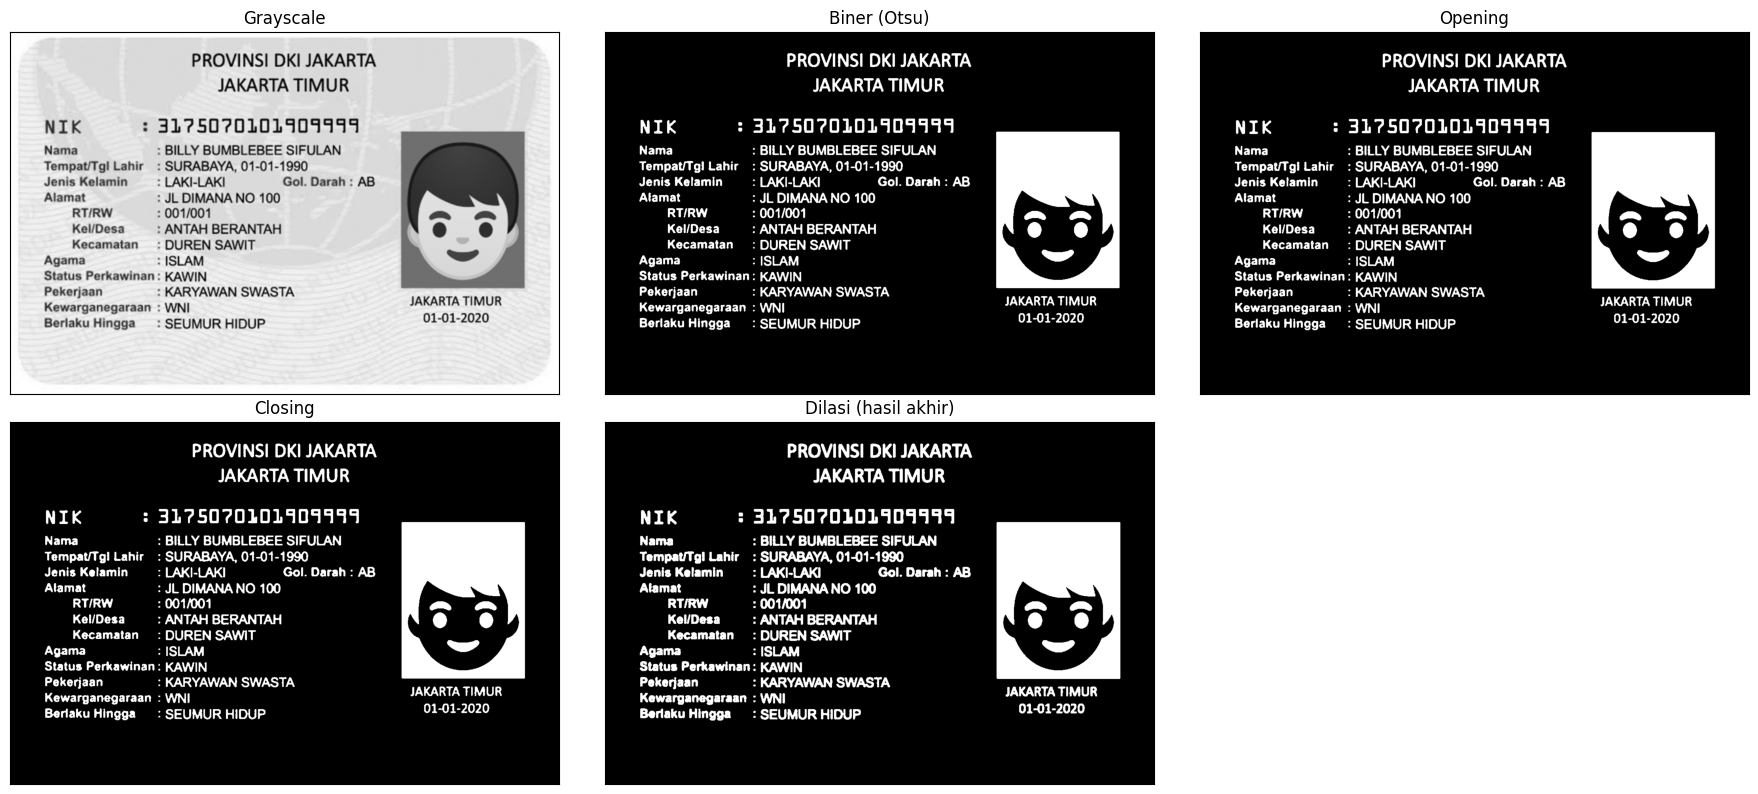

In [ ]:
# Ganti nama file sesuai gambar KTP dari Modul 7
ktp_path = IMG + 'ktp_fulan.jpg'

ktp = cv2.imread(ktp_path)
ktp = cv2.resize(ktp, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)  # perbesar agar huruf jelas
gray = cv2.cvtColor(ktp, cv2.COLOR_BGR2GRAY)
gray = cv2.GaussianBlur(gray, (3, 3), 0)

# Citra biner: huruf putih di latar hitam (THRESH_BINARY_INV) agar morfologi bekerja pada huruf
_, biner = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

k_kecil = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
k_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))

# 1) Opening: hapus bintik noise kecil
opening = cv2.morphologyEx(biner, cv2.MORPH_OPEN, k_kecil)
# 2) Closing: sambungkan huruf yang terputus
closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, k_cross)
# 3) Dilasi tipis: tebalkan huruf
dilasi = cv2.dilate(closing, k_kecil, iterations=1)

# Kembalikan ke huruf hitam di latar putih untuk OCR
hasil_morf = cv2.bitwise_not(dilasi)
tanpa_morf = cv2.bitwise_not(biner)

judul = ['Grayscale', 'Biner (Otsu)', 'Opening', 'Closing', 'Dilasi (hasil akhir)']
gambar = [gray, biner, opening, closing, dilasi]
plt.figure(figsize=(18, 8))
for n, (j, g) in enumerate(zip(judul, gambar), 1):
    plt.subplot(2, 3, n), plt.imshow(g, cmap='gray'), plt.title(j)
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

In [ ]:
cfg = '--oem 3 --psm 6'
teks_tanpa = pytesseract.image_to_string(tanpa_morf, lang='ind', config=cfg)
teks_morf  = pytesseract.image_to_string(hasil_morf, lang='ind', config=cfg)

print('=== OCR TANPA MORFOLOGI (biner saja) ===')
print(teks_tanpa)
print('\n=== OCR DENGAN MORFOLOGI (opening + closing + dilasi) ===')
print(teks_morf)

=== OCR TANPA MORFOLOGI (biner saja) ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 317?50701014011119
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgi Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga”: SEUMUR HIDUP 01-01-2020


=== OCR DENGAN MORFOLOGI (opening + closing + dilasi) ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31?5070101404114113114
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgi Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA JAKARTA TIMUR
K : WNI
Berlaku Hingga "1 SEUMUR HIDUP 01-01-2020



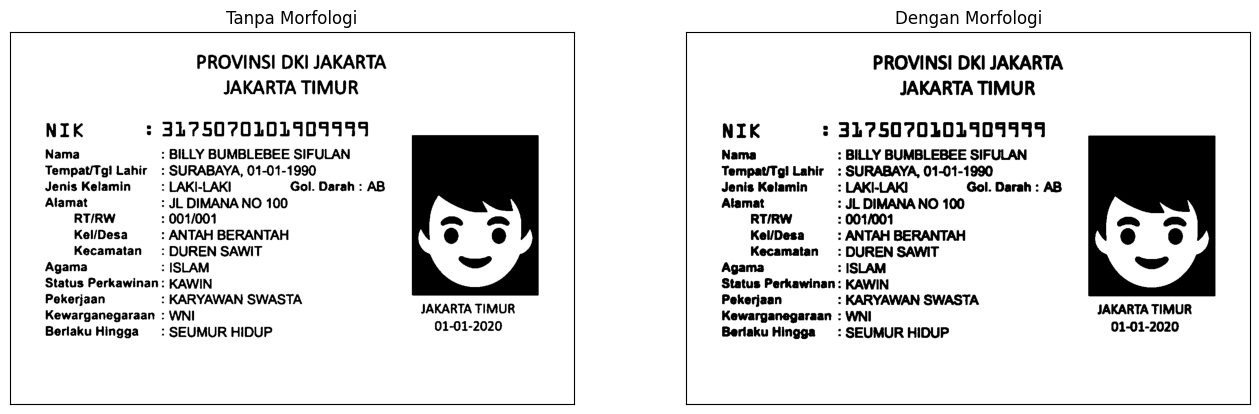

In [ ]:
# Perbandingan visual
plt.figure(figsize=(16, 6))
plt.subplot(121), plt.imshow(tanpa_morf, cmap='gray'), plt.title('Tanpa Morfologi')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(hasil_morf, cmap='gray'), plt.title('Dengan Morfologi')
plt.xticks([]), plt.yticks([])
plt.show()

### Analisis
Isi bagian ini setelah menjalankan kode: bandingkan teks hasil OCR sebelum dan sesudah morfologi (huruf yang lebih benar, noise yang hilang, huruf yang tersambung, dan sebagainya). Jika hasil kurang baik, coba ubah ukuran SE (misalnya 3x3 atau 5x5), bentuk SE (cross/rectangle), atau jumlah iterasi dilasi.